Drive loader

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Environment setup

It will run for approx 12 minutes

In [4]:
!wget -q https://nvidia.com
!dpkg -i cuda-keyring_1.1-1_all.deb
!apt-get update -qq
!apt-get -y install -qq cuda-toolkit-12-9

# Point default CUDA symlink to 12.9 and update system library cache
!rm -rf /usr/local/cuda
!ln -s /usr/local/cuda-12.9 /usr/local/cuda
!echo "/usr/local/cuda-12.9/lib64" > /etc/ld.so.conf.d/cuda-12-9.conf
!ldconfig
!pip install -q holoscan-cu12==4.6.0 nvidia-cublas-cu12


dpkg: error: cannot access archive 'cuda-keyring_1.1-1_all.deb': No such file or directory
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/sbin/ldc

In [5]:
!pip install -q cupy-cuda12x onnxruntime-gpu h5py pillow scipy


Final designed and deployable code

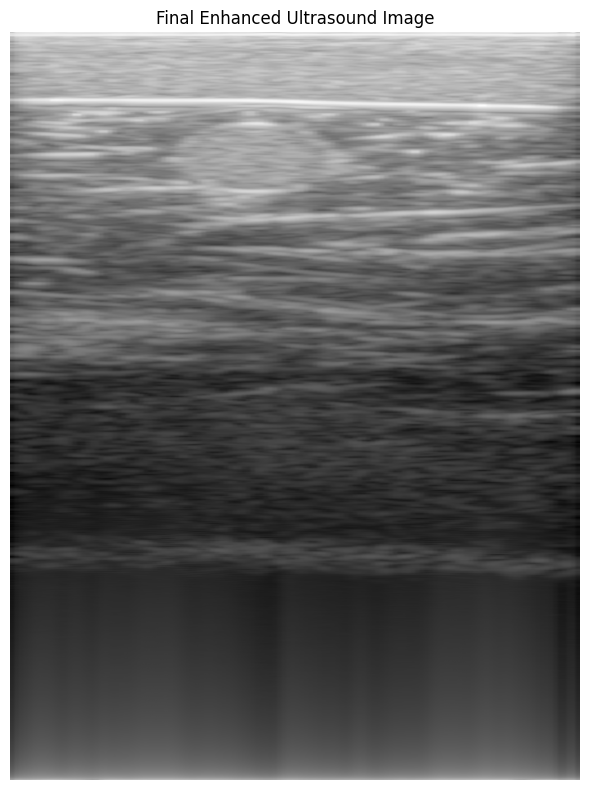

Class,Score
No_lesion,15.81%
Hypo_lesion,10.99%
Hyper_lesion,73.20%


In [7]:

# ============================================================
# FINAL RUMC ULTRASOUND IMPLEMENTATION
# HOLOSCAN 4.6.0 | CUDA 12 | GOOGLE COLAB | NVIDIA T4
#
# Headless Holoscan pipeline
#
# RF DATA + USHEADER
#       |
#       v
# MatFileSourceOp
#       |
#       v
# UltrasoundProcessingOp
#       |
#       +-- Preprocessing       (CuPy / GPU)
#       +-- FK Migration        (CuPy / GPU)
#       +-- Hilbert Transform   (CuPy / GPU)
#       +-- Normalization       (CuPy / GPU)
#       +-- Gain                (CuPy / GPU)
#       +-- Log Compression     (CuPy / GPU)
#       +-- Enhancement         (CuPy / GPU)
#       |
#       v
# ONNXInferenceOp
#       |
#       +-- ONNX Runtime CUDA
#       |
#       v
# ResultOutputOp
#       |
#       +-- Display final enhanced image
#       +-- Display CNN classification
#
# Corrections:
# 1. GPU name uses CUDA runtime properties.
# 2. RF and USHEADER loaded once in source operator.
# 3. Enhanced depth uses validated depth_coordinates.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import sys
import importlib
import contextlib
import io

import h5py
import numpy as np
import cupy as cp
import onnxruntime as ort

from cupyx.scipy.signal import hilbert

import matplotlib.pyplot as plt
from IPython.display import display, HTML

from google.colab import drive

from holoscan.core import Application, Operator
from holoscan.conditions import CountCondition


# Suppress verbose setup and pipeline logs; display() output remains visible.
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    # ============================================================
    # 2. GOOGLE DRIVE
    # ============================================================

    drive.mount("/content/drive")


    # ============================================================
    # 3. FILE PATHS
    # ============================================================

    DATA_PATH = (
        "/content/drive/MyDrive/Dataset/Hyper_lesion/"
        "USDATA_20210624113025661.mat"
    )

    HEADER_PATH = (
        "/content/drive/MyDrive/"
        "USHEADER_20210624112712.mat"
    )

    ONNX_PATH = (
        "/content/drive/MyDrive/"
        "RUMC_ThreeClass_CNN.onnx"
    )

    sys.path.append("/content/drive/MyDrive")


    # ============================================================
    # 4. VERIFY FILES
    # ============================================================

    print("\n========== FILE VERIFICATION ==========")

    for path in [DATA_PATH, HEADER_PATH, ONNX_PATH]:

        if not os.path.isfile(path):

            raise FileNotFoundError(
                f"File not found: {path}"
            )

        print("FOUND:", path)


    # ============================================================
    # 5. CUDA INITIALIZATION
    # ============================================================

    print("\n========== CUDA INITIALIZATION ==========")

    gpu_count = cp.cuda.runtime.getDeviceCount()

    if gpu_count < 1:

        raise RuntimeError(
            "No CUDA GPU detected."
        )

    device_id = 0

    device = cp.cuda.Device(device_id)

    gpu_properties = cp.cuda.runtime.getDeviceProperties(
        device_id
    )

    gpu_name = gpu_properties["name"]

    if isinstance(gpu_name, bytes):

        gpu_name = gpu_name.decode("utf-8")

    print("GPU:", gpu_name)
    print("CuPy version:", cp.__version__)

    # CUDA test

    test_gpu = cp.arange(
        10,
        dtype=cp.float32
    )

    test_result = cp.sum(test_gpu)

    cp.cuda.Stream.null.synchronize()

    print("CUDA test:", float(test_result))
    print("CUDA initialization successful.")


    # ============================================================
    # 6. IMPORT EXISTING ULTRASOUND MODULES
    # ============================================================

    print("\n========== MODULE IMPORTS ==========")

    import preprocessing
    import fkmig
    import enhancement2

    importlib.reload(preprocessing)
    importlib.reload(fkmig)
    importlib.reload(enhancement2)

    from preprocessing import preprocessing as preprocessing_function
    from fkmig import fkmig as fkmig_function
    from enhancement2 import enhancement2 as enhancement_function

    print("Preprocessing module loaded.")
    print("FK migration module loaded.")
    print("Enhancement module loaded.")


    # ============================================================
    # 7. HELPER FUNCTIONS
    # ============================================================

    def matlab_array(dataset):

        """
        Convert MATLAB v7.3 HDF5 dataset into NumPy array.
        """

        arr = np.array(dataset)

        if arr.ndim > 1:

            arr = np.transpose(
                arr,
                axes=tuple(
                    range(arr.ndim - 1, -1, -1)
                )
            )

        return arr


    def load_header_angles(header_path):

        """
        Load USHEADER transmission angles.

        Handles MATLAB object references.
        Called only once by MatFileSourceOp.
        """

        with h5py.File(
            header_path,
            "r"
        ) as f:

            if "USHEADER" not in f:

                raise KeyError(
                    "USHEADER group not found."
                )

            header_group = f["USHEADER"]

            if "xmitAngles" not in header_group:

                raise KeyError(
                    "xmitAngles not found."
                )

            angle_dataset = header_group["xmitAngles"]

            if h5py.check_dtype(
                ref=angle_dataset.dtype
            ) is not None:

                refs = angle_dataset[()].flatten()

                valid_refs = [
                    ref for ref in refs if ref
                ]

                if not valid_refs:

                    raise ValueError(
                        "No valid xmitAngles references found."
                    )

                angle_dataset = f[valid_refs[0]]

            tx_angles = matlab_array(
                angle_dataset
            ).squeeze()

            tx_angles = np.asarray(
                tx_angles,
                dtype=np.float64
            ).flatten()

        return tx_angles


    def create_reconstruction_parameters(tx_angles):

        """
        Create reconstruction parameters.
        Uses the already-loaded transmission angles.
        """

        param = {}

        param["x"] = np.linspace(
            -0.0125,
            0.0125,
            128
        )

        param["y"] = np.linspace(
            0,
            0.0725,
            500
        )

        param["fs"] = 31250000

        param["c"] = 1540

        param["p"] = 0

        param["TXangle"] = np.deg2rad(
            tx_angles
        )

        param["pitch"] = 1.953000000000000e-04

        param["passband"] = [0.3, 0.7]

        param["ncol"] = 128

        param["t0"] = 0

        return param


    def to_numpy(array):

        """
        Convert CuPy arrays to NumPy when required.
        """

        if isinstance(array, cp.ndarray):

            return cp.asnumpy(array)

        return np.asarray(array)


    def check_gpu_array(array, name):

        """
        Validate a GPU array.
        """

        if not isinstance(array, cp.ndarray):

            raise TypeError(
                f"{name} is not a CuPy GPU array."
            )

        if array.size == 0:

            raise ValueError(
                f"{name} is empty."
            )

        if not bool(
            cp.all(cp.isfinite(array)).item()
        ):

            raise ValueError(
                f"{name} contains NaN or Inf values."
            )


    # ============================================================
    # 8. ONNX SESSION INITIALIZATION
    # ============================================================

    print("\n========== ONNX INITIALIZATION ==========")

    available_providers = ort.get_available_providers()

    print(
        "Available ONNX providers:",
        available_providers
    )

    if "CUDAExecutionProvider" not in available_providers:

        raise RuntimeError(
            "ONNX Runtime CUDAExecutionProvider is unavailable."
        )

    session = ort.InferenceSession(
        ONNX_PATH,
        providers=[
            "CUDAExecutionProvider",
            "CPUExecutionProvider"
        ]
    )

    active_providers = session.get_providers()

    print(
        "Active ONNX providers:",
        active_providers
    )

    if "CUDAExecutionProvider" not in active_providers:

        raise RuntimeError(
            "ONNX CUDA provider was not activated."
        )

    input_info = session.get_inputs()[0]

    output_info = session.get_outputs()

    print("ONNX input name:", input_info.name)
    print("ONNX input shape:", input_info.shape)

    print("ONNX outputs:")

    for output in output_info:

        print(
            output.name,
            output.shape
        )


    # ============================================================
    # 9. OPERATOR 1: MAT FILE SOURCE
    #
    # Loads RF data and USHEADER exactly once.
    # ============================================================

    class MatFileSourceOp(Operator):

        def __init__(
            self,
            fragment,
            *args,
            **kwargs
        ):

            self.data_path = DATA_PATH

            self.header_path = HEADER_PATH

            super().__init__(
                fragment,
                *args,
                **kwargs
            )

        def setup(self, spec):

            spec.output(
                "ultrasound_data"
            )

        def compute(
            self,
            op_input,
            op_output,
            context
        ):

            print("\n========== LOADING INPUT FILES ==========")

            # ------------------------------------
            # Load RF data once
            # ------------------------------------

            with h5py.File(
                self.data_path,
                "r"
            ) as f:

                if "USDATA" not in f:

                    raise KeyError(
                        "USDATA dataset not found."
                    )

                sig = matlab_array(
                    f["USDATA"]
                )

                sig = np.squeeze(sig)

            print("RF data loaded.")

            print("RF shape:", sig.shape)

            # ------------------------------------
            # Load USHEADER once
            # ------------------------------------

            tx_angles = load_header_angles(
                self.header_path
            )

            USHEADER = {
                "xmitAngles": tx_angles
            }

            print("USHEADER loaded.")

            print("Transmission angles:", tx_angles)

            # ------------------------------------
            # Emit data
            # ------------------------------------

            op_output.emit(
                {
                    "sig": sig,
                    "USHEADER": USHEADER
                },
                "ultrasound_data"
            )


    # ============================================================
    # 10. OPERATOR 2: ULTRASOUND PROCESSING
    #
    # CuPy-based GPU processing.
    # ============================================================

    class UltrasoundProcessingOp(Operator):

        def setup(self, spec):

            spec.input(
                "ultrasound_data"
            )

            spec.output(
                "processed_data"
            )

        def compute(
            self,
            op_input,
            op_output,
            context
        ):

            print("\n========== ULTRASOUND PROCESSING ==========")

            data = op_input.receive(
                "ultrasound_data"
            )

            sig = data["sig"]

            USHEADER = data["USHEADER"]

            print(
                "Input RF shape:",
                sig.shape
            )

            # ------------------------------------
            # Reconstruction parameters
            # ------------------------------------

            param = create_reconstruction_parameters(
                USHEADER["xmitAngles"]
            )

            # ------------------------------------
            # PREPROCESSING
            # ------------------------------------

            print("\nRunning preprocessing...")

            useZeroDegreeOnly = False

            if useZeroDegreeOnly:

                sig_gpu, param_gpu = preprocessing_function(
                    sig,
                    USHEADER,
                    param,
                    1
                )

            else:

                sig_gpu, param_gpu = preprocessing_function(
                    sig,
                    USHEADER,
                    param
                )

            param = param_gpu

            check_gpu_array(
                sig_gpu,
                "Preprocessed RF data"
            )

            print(
                "Preprocessed shape:",
                sig_gpu.shape
            )

            # ------------------------------------
            # FK MIGRATION
            # ------------------------------------

            print("\nRunning FK migration...")

            migSIG_gpu, param = fkmig_function(
                sig_gpu,
                param
            )

            check_gpu_array(
                migSIG_gpu,
                "FK migrated data"
            )

            print(
                "FK shape:",
                migSIG_gpu.shape
            )

            # ------------------------------------
            # HILBERT TRANSFORM
            # ------------------------------------

            print("\nRunning Hilbert transform...")

            env_gpu = cp.abs(
                hilbert(
                    migSIG_gpu,
                    axis=0
                )
            )

            check_gpu_array(
                env_gpu,
                "Hilbert envelope"
            )

            # ------------------------------------
            # NORMALIZATION
            # ------------------------------------

            eps_matlab = np.finfo(
                np.float64
            ).eps

            env_max = cp.max(
                env_gpu
            )

            env_gpu = env_gpu / (
                env_max + eps_matlab
            )

            # ------------------------------------
            # GAIN
            # ------------------------------------

            gain_dB = 10

            gain = 10 ** (
                gain_dB / 20
            )

            env_enhanced_gpu = (
                env_gpu * gain
            )

            # ------------------------------------
            # LOG COMPRESSION
            # ------------------------------------

            env_dB_gpu = (
                20.0
                * cp.log10(
                    env_enhanced_gpu + eps_matlab
                )
            )

            check_gpu_array(
                env_dB_gpu,
                "Log compressed image"
            )

            # ------------------------------------
            # COORDINATE VALIDATION
            # ------------------------------------

            x_coordinates = np.asarray(
                to_numpy(param["x"])
            ).squeeze()

            if x_coordinates.size != env_dB_gpu.shape[1]:

                raise ValueError(
                    f"X coordinate length "
                    f"({x_coordinates.size}) does not match "
                    f"FK image width ({env_dB_gpu.shape[1]})."
                )

            # Select depth coordinates once.
            if "z" in param:

                depth_coordinates = np.asarray(
                    to_numpy(param["z"])
                ).squeeze()

            else:

                depth_coordinates = np.asarray(
                    to_numpy(param["y"])
                ).squeeze()

            if depth_coordinates.size != env_dB_gpu.shape[0]:

                raise ValueError(
                    f"Depth coordinate length "
                    f"({depth_coordinates.size}) does not match "
                    f"FK image height ({env_dB_gpu.shape[0]})."
                )

            # ------------------------------------
            # ENHANCEMENT
            # ------------------------------------

            print("\nRunning enhancement...")

            enhanced_img_gpu = enhancement_function(
                env_enhanced_gpu
            )

            enhanced_img_gpu = cp.squeeze(
                enhanced_img_gpu
            )

            cp.cuda.Stream.null.synchronize()

            check_gpu_array(
                enhanced_img_gpu,
                "Enhanced image"
            )

            if enhanced_img_gpu.ndim != 2:

                raise ValueError(
                    "Enhanced image must be 2D. "
                    f"Received: {enhanced_img_gpu.shape}"
                )

            enhanced_img_gpu = enhanced_img_gpu.astype(
                cp.float32,
                copy=False
            )

            print(
                "Enhanced image shape:",
                enhanced_img_gpu.shape
            )

            # ------------------------------------
            # ENHANCED IMAGE COORDINATES
            #
            # CORRECTION:
            # Reuse depth_coordinates validated above.
            # Do not independently select param['y'] or
            # param['z'] a second time.
            # ------------------------------------

            if enhanced_img_gpu.shape[1] != x_coordinates.size:

                raise ValueError(
                    f"Enhanced image width "
                    f"({enhanced_img_gpu.shape[1]}) does not match "
                    f"x coordinate length ({x_coordinates.size})."
                )

            enhanced_depth = depth_coordinates.copy()

            if enhanced_depth.size != enhanced_img_gpu.shape[0]:

                raise ValueError(
                    f"Enhanced image height "
                    f"({enhanced_img_gpu.shape[0]}) does not match "
                    f"depth coordinate length "
                    f"({enhanced_depth.size})."
                )

            print(
                "Depth coordinate length:",
                enhanced_depth.size
            )

            # ------------------------------------
            # GPU SYNCHRONIZATION
            # ------------------------------------

            cp.cuda.Stream.null.synchronize()

            # ------------------------------------
            # EMIT TO NEXT OPERATOR
            # ------------------------------------

            op_output.emit(
                {
                    "fk_image_gpu": env_dB_gpu,

                    "enhanced_image_gpu": enhanced_img_gpu,

                    "cnn_image_gpu": enhanced_img_gpu,

                    "x_coordinates": x_coordinates,

                    "depth_coordinates": depth_coordinates,

                    "enhanced_depth": enhanced_depth,

                    "param": param
                },
                "processed_data"
            )


    # ============================================================
    # 11. OPERATOR 3: ONNX INFERENCE
    #
    # ONNX Runtime CUDA execution provider.
    # ============================================================

    class ONNXInferenceOp(Operator):

        def __init__(
            self,
            fragment,
            *args,
            **kwargs
        ):

            self.session = session

            self.input_info = input_info

            self.input_name = input_info.name

            self.model_shape = input_info.shape

            super().__init__(
                fragment,
                *args,
                **kwargs
            )

        def setup(self, spec):

            spec.input(
                "processed_data"
            )

            spec.output(
                "classification_results"
            )

        def compute(
            self,
            op_input,
            op_output,
            context
        ):

            print("\n========== ONNX INFERENCE ==========")

            data = op_input.receive(
                "processed_data"
            )

            cnn_img_gpu = data[
                "cnn_image_gpu"
            ]

            check_gpu_array(
                cnn_img_gpu,
                "CNN input image"
            )

            # ------------------------------------
            # Prepare CNN dimensions
            # ------------------------------------

            cnn_img_gpu = cp.squeeze(
                cnn_img_gpu
            )

            if cnn_img_gpu.ndim != 2:

                raise ValueError(
                    "CNN input image must be 2D."
                )

            if len(self.model_shape) != 4:

                raise ValueError(
                    "Expected a 4D ONNX input shape. "
                    f"Received: {self.model_shape}"
                )

            # NCHW format
            if self.model_shape[1] == 1:

                cnn_input_gpu = cnn_img_gpu[
                    cp.newaxis,
                    cp.newaxis,
                    :,
                    :
                ]

            # NHWC format
            elif self.model_shape[3] == 1:

                cnn_input_gpu = cnn_img_gpu[
                    cp.newaxis,
                    :,
                    :,
                    cp.newaxis
                ]

            else:

                raise ValueError(
                    "Could not identify single-channel "
                    "NCHW or NHWC input."
                )

            cnn_input_gpu = cp.ascontiguousarray(
                cnn_input_gpu,
                dtype=cp.float32
            )

            # ------------------------------------
            # Validate model dimensions
            # ------------------------------------

            for actual, expected in zip(
                cnn_input_gpu.shape,
                self.model_shape
            ):

                if (
                    isinstance(expected, int)
                    and actual != expected
                ):

                    raise ValueError(
                        f"CNN input shape mismatch. "
                        f"Expected {self.model_shape}, "
                        f"received {cnn_input_gpu.shape}."
                    )

            # ------------------------------------
            # ONNX INPUT TRANSFER
            #
            # CuPy processing remains on GPU.
            # This is the host-memory boundary
            # for the standard ONNX Runtime input.
            # ------------------------------------

            cp.cuda.Stream.null.synchronize()

            cnn_input = cp.asnumpy(
                cnn_input_gpu
            )

            cnn_input = np.ascontiguousarray(
                cnn_input,
                dtype=np.float32
            )

            # ------------------------------------
            # RUN ONNX INFERENCE
            # ------------------------------------

            outputs = self.session.run(
                None,
                {
                    self.input_name: cnn_input
                }
            )

            # ------------------------------------
            # FIND THREE-CLASS OUTPUT
            # ------------------------------------

            class_output = None

            for output in outputs:

                arr = np.asarray(output)

                if arr.size == 3:

                    class_output = arr.flatten()

                    break

            if class_output is None:

                raise ValueError(
                    "Could not find an ONNX output "
                    "containing exactly three class values."
                )

            if not np.all(
                np.isfinite(class_output)
            ):

                raise ValueError(
                    "ONNX output contains NaN or Inf."
                )

            # ------------------------------------
            # SOFTMAX / PROBABILITY CONVERSION
            # ------------------------------------

            if (
                np.all(class_output >= 0)
                and np.all(class_output <= 1)
                and np.isclose(
                    np.sum(class_output),
                    1.0,
                    atol=1e-3
                )
            ):

                scores = class_output

            else:

                shifted = (
                    class_output
                    - np.max(class_output)
                )

                exp_scores = np.exp(
                    shifted
                )

                scores = (
                    exp_scores
                    / np.sum(exp_scores)
                )

            # ------------------------------------
            # CLASSIFICATION
            # ------------------------------------

            classNames = [
                "No_lesion",
                "Hypo_lesion",
                "Hyper_lesion"
            ]

            predicted_index = int(
                np.argmax(scores)
            )

            resultLabel = classNames[
                predicted_index
            ]

            print("\nClassification result:")

            print(
                "Predicted class:",
                resultLabel
            )

            for name, score in zip(
                classNames,
                scores
            ):

                print(
                    f"{name}: {score * 100:.2f}%"
                )

            # ------------------------------------
            # EMIT RESULTS
            # ------------------------------------

            op_output.emit(
                {
                    "fk_image_gpu": data["fk_image_gpu"],

                    "enhanced_image_gpu": data["enhanced_image_gpu"],

                    "cnn_input_gpu": cnn_input_gpu,

                    "x_coordinates": data["x_coordinates"],

                    "depth_coordinates": data["depth_coordinates"],

                    "enhanced_depth": data["enhanced_depth"],

                    "scores": scores,

                    "class_names": classNames,

                    "predicted_index": predicted_index,

                    "result_label": resultLabel,

                    "providers": self.session.get_providers()
                },
                "classification_results"
            )


    # ============================================================
    # 12. OPERATOR 4: RESULT DISPLAY
    #
    # Displays only the final enhanced image and CNN classification.
    # Does not save images, arrays, or classification files.
    # ============================================================

    class ResultOutputOp(Operator):

        def setup(self, spec):
            spec.input("classification_results")

        def compute(self, op_input, op_output, context):

            data = op_input.receive("classification_results")

            cp.cuda.Stream.null.synchronize()

            # ----------------------------------------------------
            # DISPLAY FINAL ENHANCED B-MODE IMAGE
            # ----------------------------------------------------

            enhanced_image = cp.asnumpy(
                data["enhanced_image_gpu"]
            )
            enhanced_image = np.squeeze(enhanced_image)

            if enhanced_image.ndim != 2:
                raise ValueError(
                    f"Final enhanced image must be 2D; got {enhanced_image.shape}."
                )

            fig, ax = plt.subplots(figsize=(6, 8))
            ax.imshow(enhanced_image, cmap="gray", aspect="auto")
            ax.set_title("Final Enhanced Ultrasound Image")
            ax.axis("off")
            fig.tight_layout()
            display(fig)
            plt.close(fig)

            # ----------------------------------------------------
            # DISPLAY CNN CLASSIFICATION AND SCORES
            # ----------------------------------------------------

            result_label = data["result_label"]
            scores = data["scores"]
            class_names = data["class_names"]

            probability_rows = "".join(
                f"<tr><td style='padding:4px 12px'>{name}</td>"
                f"<td style='padding:4px 12px;text-align:right'>"
                f"{float(score) * 100:.2f}%</td></tr>"
                for name, score in zip(class_names, scores)
            )

            display(HTML(
                f"""
                <div style="border:1px solid #888;border-radius:8px;
                            padding:12px;max-width:420px">
                    <h3 style="margin:0 0 8px 0">CNN Classification Result</h3>
                    <h2 style="margin:0 0 12px 0">{result_label}</h2>
                    <table style="border-collapse:collapse">
                        <thead><tr>
                            <th style="padding:4px 12px;text-align:left">Class</th>
                            <th style="padding:4px 12px;text-align:right">Score</th>
                        </tr></thead>
                        <tbody>{probability_rows}</tbody>
                    </table>
                </div>
                """
            ))


    # ============================================================
    # 13. HOLOSCAN APPLICATION
    # ============================================================

    class RUMCUltrasoundApp(Application):

        def compose(self):

            # ------------------------------------
            # Source operator: one execution
            # ------------------------------------

            source = MatFileSourceOp(
                self,
                CountCondition(
                    self,
                    count=1
                ),
                name="mat_file_source"
            )

            # ------------------------------------
            # GPU processing
            # ------------------------------------

            processing = UltrasoundProcessingOp(
                self,
                name="ultrasound_processing"
            )

            # ------------------------------------
            # ONNX inference
            # ------------------------------------

            inference = ONNXInferenceOp(
                self,
                name="onnx_inference"
            )

            # ------------------------------------
            # Output
            # ------------------------------------

            output = ResultOutputOp(
                self,
                name="result_output"
            )

            # ------------------------------------
            # Connect operators
            # ------------------------------------

            self.add_flow(
                source,
                processing,
                {
                    ("ultrasound_data", "ultrasound_data")
                }
            )

            self.add_flow(
                processing,
                inference,
                {
                    ("processed_data", "processed_data")
                }
            )

            self.add_flow(
                inference,
                output,
                {
                    ("classification_results", "classification_results")
                }
            )


    # ============================================================
    # 14. RUN APPLICATION
    #
    # Suppress intermediate Python/Holoscan logs. The result operator's
    # display() calls still render the final image and CNN result in Colab.
    # ============================================================

    app = RUMCUltrasoundApp()
    app.run()


Metrics and time calculation

Note: The runtime may crash due to load. dont worry! just return it as it restart session.

In [1]:

# ============================================================
# FINAL RUMC ULTRASOUND PERFORMANCE BENCHMARK
# HOLOSCAN 4.6.0 | CUDA 12.9 | GOOGLE COLAB | NVIDIA T4
#
# Metrics only:
#   Processing latency: min / max / average
#   End-to-end latency: min / max / average
#   CNN inference latency
#   Throughput
#
# No image display. No classification display. No file saving.
# ============================================================

import os
import sys
import time
import importlib

import h5py
import numpy as np
import cupy as cp
import onnxruntime as ort

from cupyx.scipy.signal import hilbert
from google.colab import drive

from holoscan.core import Application, Operator
from holoscan.conditions import CountCondition


# ============================================================
# 1. GOOGLE DRIVE AND FILE PATHS
# ============================================================

drive.mount("/content/drive")

DATA_PATH = (
    "/content/drive/MyDrive/Dataset/Hyper_lesion/"
    "USDATA_20210624113025661.mat"
)

HEADER_PATH = (
    "/content/drive/MyDrive/"
    "USHEADER_20210624112712.mat"
)

ONNX_PATH = (
    "/content/drive/MyDrive/"
    "RUMC_ThreeClass_CNN.onnx"
)

sys.path.append("/content/drive/MyDrive")

for path in [DATA_PATH, HEADER_PATH, ONNX_PATH]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"File not found: {path}")


# ============================================================
# 2. CUDA INITIALIZATION
# ============================================================

gpu_count = cp.cuda.runtime.getDeviceCount()

if gpu_count < 1:
    raise RuntimeError("No CUDA GPU detected.")

device_id = 0
device = cp.cuda.Device(device_id)
device.use()

gpu_properties = cp.cuda.runtime.getDeviceProperties(device_id)
gpu_name = gpu_properties["name"]

if isinstance(gpu_name, bytes):
    gpu_name = gpu_name.decode("utf-8")

print("GPU:", gpu_name)
print("CuPy version:", cp.__version__)


# CUDA test
test_gpu = cp.arange(10, dtype=cp.float32)
test_result = cp.sum(test_gpu)

cp.cuda.Stream.null.synchronize()

print("CUDA test:", float(test_result))


# ============================================================
# 3. IMPORT ULTRASOUND MODULES
# ============================================================

import preprocessing
import fkmig
import enhancement2

importlib.reload(preprocessing)
importlib.reload(fkmig)
importlib.reload(enhancement2)

from preprocessing import preprocessing as preprocessing_function
from fkmig import fkmig as fkmig_function
from enhancement2 import enhancement2 as enhancement_function


# ============================================================
# 4. PERFORMANCE TIMING STORAGE
# ============================================================

timing_data = {
    "pipeline_start": None,
    "processing_latency": [],
    "inference_latency": [],
    "total_latency": []
}


# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def matlab_array(dataset):
    """Convert MATLAB v7.3 HDF5 dataset to NumPy array."""

    arr = np.array(dataset)

    if arr.ndim > 1:
        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1))
        )

    return arr


def load_header_angles(header_path):
    """Load transmission angles from USHEADER."""

    with h5py.File(header_path, "r") as f:

        if "USHEADER" not in f:
            raise KeyError("USHEADER group not found.")

        header_group = f["USHEADER"]

        if "xmitAngles" not in header_group:
            raise KeyError("xmitAngles not found.")

        angle_dataset = header_group["xmitAngles"]

        if h5py.check_dtype(ref=angle_dataset.dtype) is not None:

            refs = angle_dataset[()].flatten()
            valid_refs = [ref for ref in refs if ref]

            if not valid_refs:
                raise ValueError(
                    "No valid xmitAngles references found."
                )

            angle_dataset = f[valid_refs[0]]

        tx_angles = matlab_array(angle_dataset).squeeze()

        tx_angles = np.asarray(
            tx_angles,
            dtype=np.float64
        ).flatten()

    return tx_angles


def create_reconstruction_parameters(tx_angles):

    param = {}

    param["x"] = np.linspace(-0.0125, 0.0125, 128)
    param["y"] = np.linspace(0, 0.0725, 500)

    param["fs"] = 31250000
    param["c"] = 1540
    param["p"] = 0

    param["TXangle"] = np.deg2rad(tx_angles)

    param["pitch"] = 1.953000000000000e-04
    param["passband"] = [0.3, 0.7]
    param["ncol"] = 128
    param["t0"] = 0

    return param


def to_numpy(array):

    if isinstance(array, cp.ndarray):
        return cp.asnumpy(array)

    return np.asarray(array)


def check_gpu_array(array, name):

    if not isinstance(array, cp.ndarray):
        raise TypeError(
            f"{name} is not a CuPy GPU array."
        )

    if array.size == 0:
        raise ValueError(f"{name} is empty.")

    if not bool(cp.all(cp.isfinite(array)).item()):
        raise ValueError(
            f"{name} contains NaN or Inf values."
        )


# ============================================================
# 6. ONNX SESSION INITIALIZATION
# ============================================================

available_providers = ort.get_available_providers()

print("ONNX providers:", available_providers)

if "CUDAExecutionProvider" not in available_providers:
    raise RuntimeError(
        "ONNX Runtime CUDAExecutionProvider unavailable."
    )

session = ort.InferenceSession(
    ONNX_PATH,
    providers=[
        "CUDAExecutionProvider",
        "CPUExecutionProvider"
    ]
)

if "CUDAExecutionProvider" not in session.get_providers():
    raise RuntimeError(
        "ONNX CUDA provider was not activated."
    )

input_info = session.get_inputs()[0]
output_info = session.get_outputs()

print("ONNX input:", input_info.name)
print("ONNX input shape:", input_info.shape)

for output in output_info:
    print("ONNX output:", output.name, output.shape)


# ============================================================
# 7. OPERATOR 1: MAT FILE SOURCE
# ============================================================

class MatFileSourceOp(Operator):

    def setup(self, spec):
        spec.output("ultrasound_data")

    def compute(self, op_input, op_output, context):

        # Start end-to-end timer before loading files.
        timing_data["pipeline_start"] = time.perf_counter()

        with h5py.File(DATA_PATH, "r") as f:

            if "USDATA" not in f:
                raise KeyError("USDATA dataset not found.")

            sig = matlab_array(f["USDATA"])
            sig = np.squeeze(sig)

        tx_angles = load_header_angles(HEADER_PATH)

        USHEADER = {
            "xmitAngles": tx_angles
        }

        op_output.emit(
            {
                "sig": sig,
                "USHEADER": USHEADER
            },
            "ultrasound_data"
        )


# ============================================================
# 8. OPERATOR 2: ULTRASOUND PROCESSING
# ============================================================

class UltrasoundProcessingOp(Operator):

    def setup(self, spec):
        spec.input("ultrasound_data")
        spec.output("processed_data")

    def compute(self, op_input, op_output, context):

        data = op_input.receive("ultrasound_data")

        sig = data["sig"]
        USHEADER = data["USHEADER"]

        # Start processing timer.
        cp.cuda.Stream.null.synchronize()
        processing_start = time.perf_counter()

        param = create_reconstruction_parameters(
            USHEADER["xmitAngles"]
        )

        # ----------------------------------------------------
        # PREPROCESSING
        # ----------------------------------------------------

        useZeroDegreeOnly = False

        if useZeroDegreeOnly:

            sig_gpu, param_gpu = preprocessing_function(
                sig,
                USHEADER,
                param,
                1
            )

        else:

            sig_gpu, param_gpu = preprocessing_function(
                sig,
                USHEADER,
                param
            )

        param = param_gpu

        check_gpu_array(sig_gpu, "Preprocessed RF data")

        # ----------------------------------------------------
        # FK MIGRATION
        # ----------------------------------------------------

        migSIG_gpu, param = fkmig_function(
            sig_gpu,
            param
        )

        check_gpu_array(migSIG_gpu, "FK migrated data")

        # ----------------------------------------------------
        # HILBERT TRANSFORM
        # ----------------------------------------------------

        env_gpu = cp.abs(
            hilbert(migSIG_gpu, axis=0)
        )

        check_gpu_array(env_gpu, "Hilbert envelope")

        # ----------------------------------------------------
        # NORMALIZATION
        # ----------------------------------------------------

        eps_matlab = np.finfo(np.float64).eps

        env_max = cp.max(env_gpu)

        env_gpu = env_gpu / (
            env_max + eps_matlab
        )

        # ----------------------------------------------------
        # GAIN
        # ----------------------------------------------------

        gain_dB = 10

        gain = 10 ** (gain_dB / 20)

        env_enhanced_gpu = env_gpu * gain

        # ----------------------------------------------------
        # LOG COMPRESSION
        # ----------------------------------------------------

        env_dB_gpu = (
            20.0
            * cp.log10(
                env_enhanced_gpu + eps_matlab
            )
        )

        check_gpu_array(
            env_dB_gpu,
            "Log compressed image"
        )

        # ----------------------------------------------------
        # COORDINATE VALIDATION
        # ----------------------------------------------------

        x_coordinates = np.asarray(
            to_numpy(param["x"])
        ).squeeze()

        if x_coordinates.size != env_dB_gpu.shape[1]:
            raise ValueError(
                "X coordinate length does not match FK width."
            )

        if "z" in param:

            depth_coordinates = np.asarray(
                to_numpy(param["z"])
            ).squeeze()

        else:

            depth_coordinates = np.asarray(
                to_numpy(param["y"])
            ).squeeze()

        if depth_coordinates.size != env_dB_gpu.shape[0]:
            raise ValueError(
                "Depth coordinate length does not match FK height."
            )

        # ----------------------------------------------------
        # ENHANCEMENT
        # ----------------------------------------------------

        enhanced_img_gpu = enhancement_function(
            env_enhanced_gpu
        )

        enhanced_img_gpu = cp.squeeze(
            enhanced_img_gpu
        )

        cp.cuda.Stream.null.synchronize()

        check_gpu_array(
            enhanced_img_gpu,
            "Enhanced image"
        )

        if enhanced_img_gpu.ndim != 2:
            raise ValueError(
                "Enhanced image must be 2D."
            )

        enhanced_img_gpu = enhanced_img_gpu.astype(
            cp.float32,
            copy=False
        )

        enhanced_depth = depth_coordinates.copy()

        if enhanced_img_gpu.shape[1] != x_coordinates.size:
            raise ValueError(
                "Enhanced image width mismatch."
            )

        if enhanced_img_gpu.shape[0] != enhanced_depth.size:
            raise ValueError(
                "Enhanced image depth mismatch."
            )

        # ----------------------------------------------------
        # END PROCESSING TIMER
        # ----------------------------------------------------

        cp.cuda.Stream.null.synchronize()

        processing_end = time.perf_counter()

        processing_latency = (
            processing_end - processing_start
        )

        timing_data["processing_latency"].append(
            processing_latency
        )

        # ----------------------------------------------------
        # EMIT DATA
        # ----------------------------------------------------

        op_output.emit(
            {
                "fk_image_gpu": env_dB_gpu,
                "enhanced_image_gpu": enhanced_img_gpu,
                "cnn_image_gpu": enhanced_img_gpu,
                "x_coordinates": x_coordinates,
                "depth_coordinates": depth_coordinates,
                "enhanced_depth": enhanced_depth,
                "param": param
            },
            "processed_data"
        )


# ============================================================
# 9. OPERATOR 3: ONNX INFERENCE
# ============================================================

class ONNXInferenceOp(Operator):

    def __init__(self, fragment, *args, **kwargs):

        self.session = session
        self.input_info = input_info
        self.input_name = input_info.name
        self.model_shape = input_info.shape

        super().__init__(fragment, *args, **kwargs)

    def setup(self, spec):
        spec.input("processed_data")
        spec.output("classification_results")

    def compute(self, op_input, op_output, context):

        data = op_input.receive("processed_data")

        cnn_img_gpu = data["cnn_image_gpu"]

        check_gpu_array(
            cnn_img_gpu,
            "CNN input image"
        )

        cnn_img_gpu = cp.squeeze(cnn_img_gpu)

        if cnn_img_gpu.ndim != 2:
            raise ValueError(
                "CNN input image must be 2D."
            )

        if len(self.model_shape) != 4:
            raise ValueError(
                "Expected a 4D ONNX input shape."
            )

        # ----------------------------------------------------
        # PREPARE CNN INPUT
        # ----------------------------------------------------

        if self.model_shape[1] == 1:

            cnn_input_gpu = cnn_img_gpu[
                cp.newaxis,
                cp.newaxis,
                :, :
            ]

        elif self.model_shape[3] == 1:

            cnn_input_gpu = cnn_img_gpu[
                cp.newaxis,
                :, :,
                cp.newaxis
            ]

        else:

            raise ValueError(
                "Could not identify NCHW or NHWC input."
            )

        cnn_input_gpu = cp.ascontiguousarray(
            cnn_input_gpu,
            dtype=cp.float32
        )

        for actual, expected in zip(
            cnn_input_gpu.shape,
            self.model_shape
        ):

            if isinstance(expected, int) and actual != expected:
                raise ValueError(
                    f"Input shape mismatch: "
                    f"{cnn_input_gpu.shape} vs {self.model_shape}"
                )

        # ----------------------------------------------------
        # GPU SYNCHRONIZATION BEFORE INFERENCE
        # ----------------------------------------------------

        cp.cuda.Stream.null.synchronize()

        cnn_input = cp.asnumpy(cnn_input_gpu)

        cnn_input = np.ascontiguousarray(
            cnn_input,
            dtype=np.float32
        )

        # ----------------------------------------------------
        # CNN INFERENCE TIMER
        # ----------------------------------------------------

        inference_start = time.perf_counter()

        outputs = self.session.run(
            None,
            {
                self.input_name: cnn_input
            }
        )

        # Synchronize GPU after inference for accurate timing.
        cp.cuda.Stream.null.synchronize()

        inference_end = time.perf_counter()

        inference_latency = (
            inference_end - inference_start
        )

        timing_data["inference_latency"].append(
            inference_latency
        )

        # ----------------------------------------------------
        # CLASS OUTPUT
        # ----------------------------------------------------

        class_output = None

        for output in outputs:

            arr = np.asarray(output)

            if arr.size == 3:
                class_output = arr.flatten()
                break

        if class_output is None:
            raise ValueError(
                "Could not find three-class ONNX output."
            )

        if not np.all(np.isfinite(class_output)):
            raise ValueError(
                "ONNX output contains NaN or Inf."
            )

        # ----------------------------------------------------
        # PROBABILITY CONVERSION
        # ----------------------------------------------------

        if (
            np.all(class_output >= 0)
            and np.all(class_output <= 1)
            and np.isclose(
                np.sum(class_output),
                1.0,
                atol=1e-3
            )
        ):

            scores = class_output

        else:

            shifted = (
                class_output - np.max(class_output)
            )

            exp_scores = np.exp(shifted)

            scores = (
                exp_scores / np.sum(exp_scores)
            )

        classNames = [
            "No_lesion",
            "Hypo_lesion",
            "Hyper_lesion"
        ]

        predicted_index = int(
            np.argmax(scores)
        )

        resultLabel = classNames[
            predicted_index
        ]

        # ----------------------------------------------------
        # EMIT RESULTS
        # ----------------------------------------------------

        op_output.emit(
            {
                "scores": scores,
                "class_names": classNames,
                "predicted_index": predicted_index,
                "result_label": resultLabel
            },
            "classification_results"
        )


# ============================================================
# 10. OPERATOR 4: METRICS OUTPUT
# ============================================================

class ResultOutputOp(Operator):

    def setup(self, spec):
        spec.input("classification_results")

    def compute(self, op_input, op_output, context):

        op_input.receive("classification_results")

        cp.cuda.Stream.null.synchronize()

        pipeline_start = timing_data["pipeline_start"]

        if pipeline_start is None:
            raise RuntimeError(
                "Pipeline timer was not initialized."
            )

        pipeline_end = time.perf_counter()

        total_latency = (
            pipeline_end - pipeline_start
        )

        timing_data["total_latency"].append(
            total_latency
        )

        processing_times = np.asarray(
            timing_data["processing_latency"],
            dtype=np.float64
        )

        inference_times = np.asarray(
            timing_data["inference_latency"],
            dtype=np.float64
        )

        total_times = np.asarray(
            timing_data["total_latency"],
            dtype=np.float64
        )

        if processing_times.size == 0:
            raise RuntimeError(
                "No processing timing measurements."
            )

        # ----------------------------------------------------
        # PROCESSING LATENCY STATISTICS
        # ----------------------------------------------------

        processing_min = np.min(processing_times)
        processing_max = np.max(processing_times)
        processing_avg = np.mean(processing_times)

        # ----------------------------------------------------
        # END-TO-END LATENCY STATISTICS
        # ----------------------------------------------------

        total_min = np.min(total_times)
        total_max = np.max(total_times)
        total_avg = np.mean(total_times)

        # ----------------------------------------------------
        # THROUGHPUT
        # ----------------------------------------------------

        sample_count = len(total_times)

        elapsed_time = (
            pipeline_end - pipeline_start
        )

        throughput = (
            sample_count / elapsed_time
            if elapsed_time > 0
            else 0.0
        )

        # ----------------------------------------------------
        # DISPLAY METRICS ONLY
        # ----------------------------------------------------

        print("\n" + "=" * 60)
        print("FINAL RUMC ULTRASOUND PERFORMANCE METRICS")
        print("=" * 60)

        print("\n--- Processing Latency ---")

        print(
            f"Minimum Latency : {processing_min:.6f} sec"
        )

        print(
            f"Maximum Latency : {processing_max:.6f} sec"
        )

        print(
            f"Average Latency : {processing_avg:.6f} sec"
        )

        print("\n--- End-to-End Latency ---")

        print(
            f"Minimum Latency : {total_min:.6f} sec"
        )

        print(
            f"Maximum Latency : {total_max:.6f} sec"
        )

        print(
            f"Average Latency : {total_avg:.6f} sec"
        )

        print("\n--- CNN Inference ---")

        if inference_times.size > 0:

            print(
                f"Average Inference Latency : "
                f"{np.mean(inference_times):.6f} sec"
            )

        print("\n--- Throughput ---")

        print(
            f"Samples Processed : {sample_count}"
        )

        print(
            f"Throughput        : {throughput:.4f} samples/sec"
        )

        print(
            f"Throughput        : "
            f"{throughput * 60:.2f} samples/min"
        )

        print("=" * 60)


# ============================================================
# 11. HOLOSCAN APPLICATION
# ============================================================

class RUMCUltrasoundApp(Application):

    def compose(self):

        source = MatFileSourceOp(
            self,
            CountCondition(self, count=1),
            name="mat_file_source"
        )

        processing = UltrasoundProcessingOp(
            self,
            name="ultrasound_processing"
        )

        inference = ONNXInferenceOp(
            self,
            name="onnx_inference"
        )

        output = ResultOutputOp(
            self,
            name="result_output"
        )

        self.add_flow(
            source,
            processing,
            {("ultrasound_data", "ultrasound_data")}
        )

        self.add_flow(
            processing,
            inference,
            {("processed_data", "processed_data")}
        )

        self.add_flow(
            inference,
            output,
            {("classification_results", "classification_results")}
        )


# ============================================================
# 12. RUN APPLICATION
# ============================================================

app = RUMCUltrasoundApp()
app.run()


/usr/local/lib/python3.13/dist-packages/cupy/_environment.py:596: UserWarning: 
--------------------------------------------------------------------------------

  CuPy may not function correctly because multiple CuPy packages are installed
  in your environment:

    cupy-cuda12x, cupy-cuda13x

  Follow these steps to resolve this issue:

    1. For all packages listed above, run the following command to remove all
       existing CuPy installations:

         $ pip uninstall <package_name>

      If you previously installed CuPy via conda, also run the following:

         $ conda uninstall cupy

    2. Install the appropriate CuPy package.
       Refer to the Installation Guide for detailed instructions.

         https://docs.cupy.dev/en/stable/install.html

--------------------------------------------------------------------------------

  warnings.warn(f'''
/usr/local/lib/python3.13/dist-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
CuPy version: 13.6.0
CUDA test: 45.0
ONNX providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
ONNX input: input
ONNX input shape: ['BatchSize', 1, 2848, 128]
ONNX output: softmax ['BatchSize', 3]

CUDA Ultrasound preprocessing completed.
GPU: b'Tesla T4'
Remaining samples: 2848
Number of channels: 128
Number of transmission angles: 75
Output device: CUDA GPU
Output dtype: float64
Output shape: (2848, 128, 75)

CUDA FK migration completed.
GPU: b'Tesla T4'
Output shape: (2848, 128)
Output dtype: float64
Output device: CUDA GPU

FINAL RUMC ULTRASOUND PERFORMANCE METRICS

--- Processing Latency ---
Minimum Latency : 7.328978 sec
Maximum Latency : 7.328978 sec
Average Latency : 7.328978 sec

--- End-to-End Latency ---
Minimum Latency : 7.889467 sec
Maximum Latency : 7.889467 sec
Average Latency : 7.889467 sec

-

Batch-based processing example code

In [2]:

# ============================================================
# FINAL RUMC ULTRASOUND IMPLEMENTATION
# HOLOSCAN 4.6.0 | CUDA 12 | GOOGLE COLAB | NVIDIA T4
#
# Headless Holoscan pipeline
#
# RF DATA + USHEADER
#       |
#       v
# MatFileSourceOp
#       |
#       v
# UltrasoundProcessingOp
#       |
#       +-- Preprocessing       (CuPy / GPU)
#       +-- FK Migration        (CuPy / GPU)
#       +-- Hilbert Transform   (CuPy / GPU)
#       +-- Normalization       (CuPy / GPU)
#       +-- Gain                (CuPy / GPU)
#       +-- Log Compression     (CuPy / GPU)
#       +-- Enhancement         (CuPy / GPU)
#       |
#       v
# ONNXInferenceOp
#       |
#       +-- ONNX Runtime CUDA
#       |
#       v
# ResultOutputOp
#       |
#       +-- Display final enhanced image
#       +-- Display CNN classification
#
# Corrections:
# 1. GPU name uses CUDA runtime properties.
# 2. RF and USHEADER loaded once in source operator.
# 3. Enhanced depth uses validated depth_coordinates.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import sys
import importlib
import contextlib
import io

import h5py
import numpy as np
import cupy as cp
import onnxruntime as ort

from cupyx.scipy.signal import hilbert

import matplotlib.pyplot as plt
from IPython.display import display, HTML

from google.colab import drive

from holoscan.core import Application, Operator
from holoscan.conditions import CountCondition


# Suppress verbose setup and pipeline logs; display() output remains visible.
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    # ============================================================
    # 2. GOOGLE DRIVE
    # ============================================================

    drive.mount("/content/drive")


    # ============================================================
    # 3. FILE PATHS
    # ============================================================

    DATASET_ROOT = "/content/drive/MyDrive/Dataset"
    OUTPUT_ROOT = "/content/drive/MyDrive/Dataset_Results"
    DATA_PATH = ""  # Updated for each raw input file
    CURRENT_OUTPUT_DIR = ""
    CURRENT_OUTPUT_BASENAME = ""

    HEADER_PATH = (
        "/content/drive/MyDrive/"
        "USHEADER_20210624112712.mat"
    )

    ONNX_PATH = (
        "/content/drive/MyDrive/"
        "RUMC_ThreeClass_CNN.onnx"
    )

    sys.path.append("/content/drive/MyDrive")


    # ============================================================
    # 4. VERIFY FILES
    # ============================================================

    print("\n========== FILE VERIFICATION ==========")

    for path in [HEADER_PATH, ONNX_PATH]:

        if not os.path.isfile(path):

            raise FileNotFoundError(
                f"Required file not found: {path}"
            )

    if not os.path.isdir(DATASET_ROOT):
        raise FileNotFoundError(f"Dataset folder not found: {DATASET_ROOT}")

    # Recursively find raw MATLAB RF files in all dataset subfolders.
    raw_files = sorted(
        path for path in __import__("glob").glob(
            os.path.join(DATASET_ROOT, "**", "USDATA*.mat"), recursive=True
        )
        if os.path.isfile(path)
    )

    if not raw_files:
        raise FileNotFoundError(
            f"No USDATA*.mat raw files found under {DATASET_ROOT}"
        )

    os.makedirs(OUTPUT_ROOT, exist_ok=True)



    # ============================================================
    # 5. CUDA INITIALIZATION
    # ============================================================

    print("\n========== CUDA INITIALIZATION ==========")

    gpu_count = cp.cuda.runtime.getDeviceCount()

    if gpu_count < 1:

        raise RuntimeError(
            "No CUDA GPU detected."
        )

    device_id = 0

    device = cp.cuda.Device(device_id)

    gpu_properties = cp.cuda.runtime.getDeviceProperties(
        device_id
    )

    gpu_name = gpu_properties["name"]

    if isinstance(gpu_name, bytes):

        gpu_name = gpu_name.decode("utf-8")

    print("GPU:", gpu_name)
    print("CuPy version:", cp.__version__)

    # CUDA test

    test_gpu = cp.arange(
        10,
        dtype=cp.float32
    )

    test_result = cp.sum(test_gpu)

    cp.cuda.Stream.null.synchronize()

    print("CUDA test:", float(test_result))
    print("CUDA initialization successful.")


    # ============================================================
    # 6. IMPORT EXISTING ULTRASOUND MODULES
    # ============================================================

    print("\n========== MODULE IMPORTS ==========")

    import preprocessing
    import fkmig
    import enhancement2

    importlib.reload(preprocessing)
    importlib.reload(fkmig)
    importlib.reload(enhancement2)

    from preprocessing import preprocessing as preprocessing_function
    from fkmig import fkmig as fkmig_function
    from enhancement2 import enhancement2 as enhancement_function

    print("Preprocessing module loaded.")
    print("FK migration module loaded.")
    print("Enhancement module loaded.")


    # ============================================================
    # 7. HELPER FUNCTIONS
    # ============================================================

    def matlab_array(dataset):

        """
        Convert MATLAB v7.3 HDF5 dataset into NumPy array.
        """

        arr = np.array(dataset)

        if arr.ndim > 1:

            arr = np.transpose(
                arr,
                axes=tuple(
                    range(arr.ndim - 1, -1, -1)
                )
            )

        return arr


    def load_header_angles(header_path):

        """
        Load USHEADER transmission angles.

        Handles MATLAB object references.
        Called only once by MatFileSourceOp.
        """

        with h5py.File(
            header_path,
            "r"
        ) as f:

            if "USHEADER" not in f:

                raise KeyError(
                    "USHEADER group not found."
                )

            header_group = f["USHEADER"]

            if "xmitAngles" not in header_group:

                raise KeyError(
                    "xmitAngles not found."
                )

            angle_dataset = header_group["xmitAngles"]

            if h5py.check_dtype(
                ref=angle_dataset.dtype
            ) is not None:

                refs = angle_dataset[()].flatten()

                valid_refs = [
                    ref for ref in refs if ref
                ]

                if not valid_refs:

                    raise ValueError(
                        "No valid xmitAngles references found."
                    )

                angle_dataset = f[valid_refs[0]]

            tx_angles = matlab_array(
                angle_dataset
            ).squeeze()

            tx_angles = np.asarray(
                tx_angles,
                dtype=np.float64
            ).flatten()

        return tx_angles


    def create_reconstruction_parameters(tx_angles):

        """
        Create reconstruction parameters.
        Uses the already-loaded transmission angles.
        """

        param = {}

        param["x"] = np.linspace(
            -0.0125,
            0.0125,
            128
        )

        param["y"] = np.linspace(
            0,
            0.0725,
            500
        )

        param["fs"] = 31250000

        param["c"] = 1540

        param["p"] = 0

        param["TXangle"] = np.deg2rad(
            tx_angles
        )

        param["pitch"] = 1.953000000000000e-04

        param["passband"] = [0.3, 0.7]

        param["ncol"] = 128

        param["t0"] = 0

        return param


    def to_numpy(array):

        """
        Convert CuPy arrays to NumPy when required.
        """

        if isinstance(array, cp.ndarray):

            return cp.asnumpy(array)

        return np.asarray(array)


    def check_gpu_array(array, name):

        """
        Validate a GPU array.
        """

        if not isinstance(array, cp.ndarray):

            raise TypeError(
                f"{name} is not a CuPy GPU array."
            )

        if array.size == 0:

            raise ValueError(
                f"{name} is empty."
            )

        if not bool(
            cp.all(cp.isfinite(array)).item()
        ):

            raise ValueError(
                f"{name} contains NaN or Inf values."
            )


    # ============================================================
    # 8. ONNX SESSION INITIALIZATION
    # ============================================================

    print("\n========== ONNX INITIALIZATION ==========")

    available_providers = ort.get_available_providers()

    print(
        "Available ONNX providers:",
        available_providers
    )

    if "CUDAExecutionProvider" not in available_providers:

        raise RuntimeError(
            "ONNX Runtime CUDAExecutionProvider is unavailable."
        )

    session = ort.InferenceSession(
        ONNX_PATH,
        providers=[
            "CUDAExecutionProvider",
            "CPUExecutionProvider"
        ]
    )

    active_providers = session.get_providers()

    print(
        "Active ONNX providers:",
        active_providers
    )

    if "CUDAExecutionProvider" not in active_providers:

        raise RuntimeError(
            "ONNX CUDA provider was not activated."
        )

    input_info = session.get_inputs()[0]

    output_info = session.get_outputs()

    print("ONNX input name:", input_info.name)
    print("ONNX input shape:", input_info.shape)

    print("ONNX outputs:")

    for output in output_info:

        print(
            output.name,
            output.shape
        )


    # ============================================================
    # 9. OPERATOR 1: MAT FILE SOURCE
    #
    # Loads RF data and USHEADER exactly once.
    # ============================================================

    class MatFileSourceOp(Operator):

        def __init__(
            self,
            fragment,
            *args,
            **kwargs
        ):

            self.data_path = DATA_PATH

            self.header_path = HEADER_PATH

            super().__init__(
                fragment,
                *args,
                **kwargs
            )

        def setup(self, spec):

            spec.output(
                "ultrasound_data"
            )

        def compute(
            self,
            op_input,
            op_output,
            context
        ):

            print("\n========== LOADING INPUT FILES ==========")

            # ------------------------------------
            # Load RF data once
            # ------------------------------------

            with h5py.File(
                self.data_path,
                "r"
            ) as f:

                if "USDATA" not in f:

                    raise KeyError(
                        "USDATA dataset not found."
                    )

                sig = matlab_array(
                    f["USDATA"]
                )

                sig = np.squeeze(sig)

            print("RF data loaded.")

            print("RF shape:", sig.shape)

            # ------------------------------------
            # Load USHEADER once
            # ------------------------------------

            tx_angles = load_header_angles(
                self.header_path
            )

            USHEADER = {
                "xmitAngles": tx_angles
            }

            print("USHEADER loaded.")

            print("Transmission angles:", tx_angles)

            # ------------------------------------
            # Emit data
            # ------------------------------------

            op_output.emit(
                {
                    "sig": sig,
                    "USHEADER": USHEADER
                },
                "ultrasound_data"
            )


    # ============================================================
    # 10. OPERATOR 2: ULTRASOUND PROCESSING
    #
    # CuPy-based GPU processing.
    # ============================================================

    class UltrasoundProcessingOp(Operator):

        def setup(self, spec):

            spec.input(
                "ultrasound_data"
            )

            spec.output(
                "processed_data"
            )

        def compute(
            self,
            op_input,
            op_output,
            context
        ):

            print("\n========== ULTRASOUND PROCESSING ==========")

            data = op_input.receive(
                "ultrasound_data"
            )

            sig = data["sig"]

            USHEADER = data["USHEADER"]

            print(
                "Input RF shape:",
                sig.shape
            )

            # ------------------------------------
            # Reconstruction parameters
            # ------------------------------------

            param = create_reconstruction_parameters(
                USHEADER["xmitAngles"]
            )

            # ------------------------------------
            # PREPROCESSING
            # ------------------------------------

            print("\nRunning preprocessing...")

            useZeroDegreeOnly = False

            if useZeroDegreeOnly:

                sig_gpu, param_gpu = preprocessing_function(
                    sig,
                    USHEADER,
                    param,
                    1
                )

            else:

                sig_gpu, param_gpu = preprocessing_function(
                    sig,
                    USHEADER,
                    param
                )

            param = param_gpu

            check_gpu_array(
                sig_gpu,
                "Preprocessed RF data"
            )

            print(
                "Preprocessed shape:",
                sig_gpu.shape
            )

            # ------------------------------------
            # FK MIGRATION
            # ------------------------------------

            print("\nRunning FK migration...")

            migSIG_gpu, param = fkmig_function(
                sig_gpu,
                param
            )

            check_gpu_array(
                migSIG_gpu,
                "FK migrated data"
            )

            print(
                "FK shape:",
                migSIG_gpu.shape
            )

            # ------------------------------------
            # HILBERT TRANSFORM
            # ------------------------------------

            print("\nRunning Hilbert transform...")

            env_gpu = cp.abs(
                hilbert(
                    migSIG_gpu,
                    axis=0
                )
            )

            check_gpu_array(
                env_gpu,
                "Hilbert envelope"
            )

            # ------------------------------------
            # NORMALIZATION
            # ------------------------------------

            eps_matlab = np.finfo(
                np.float64
            ).eps

            env_max = cp.max(
                env_gpu
            )

            env_gpu = env_gpu / (
                env_max + eps_matlab
            )

            # ------------------------------------
            # GAIN
            # ------------------------------------

            gain_dB = 10

            gain = 10 ** (
                gain_dB / 20
            )

            env_enhanced_gpu = (
                env_gpu * gain
            )

            # ------------------------------------
            # LOG COMPRESSION
            # ------------------------------------

            env_dB_gpu = (
                20.0
                * cp.log10(
                    env_enhanced_gpu + eps_matlab
                )
            )

            check_gpu_array(
                env_dB_gpu,
                "Log compressed image"
            )

            # ------------------------------------
            # COORDINATE VALIDATION
            # ------------------------------------

            x_coordinates = np.asarray(
                to_numpy(param["x"])
            ).squeeze()

            if x_coordinates.size != env_dB_gpu.shape[1]:

                raise ValueError(
                    f"X coordinate length "
                    f"({x_coordinates.size}) does not match "
                    f"FK image width ({env_dB_gpu.shape[1]})."
                )

            # Select depth coordinates once.
            if "z" in param:

                depth_coordinates = np.asarray(
                    to_numpy(param["z"])
                ).squeeze()

            else:

                depth_coordinates = np.asarray(
                    to_numpy(param["y"])
                ).squeeze()

            if depth_coordinates.size != env_dB_gpu.shape[0]:

                raise ValueError(
                    f"Depth coordinate length "
                    f"({depth_coordinates.size}) does not match "
                    f"FK image height ({env_dB_gpu.shape[0]})."
                )

            # ------------------------------------
            # ENHANCEMENT
            # ------------------------------------

            print("\nRunning enhancement...")

            enhanced_img_gpu = enhancement_function(
                env_enhanced_gpu
            )

            enhanced_img_gpu = cp.squeeze(
                enhanced_img_gpu
            )

            cp.cuda.Stream.null.synchronize()

            check_gpu_array(
                enhanced_img_gpu,
                "Enhanced image"
            )

            if enhanced_img_gpu.ndim != 2:

                raise ValueError(
                    "Enhanced image must be 2D. "
                    f"Received: {enhanced_img_gpu.shape}"
                )

            enhanced_img_gpu = enhanced_img_gpu.astype(
                cp.float32,
                copy=False
            )

            print(
                "Enhanced image shape:",
                enhanced_img_gpu.shape
            )

            # ------------------------------------
            # ENHANCED IMAGE COORDINATES
            #
            # CORRECTION:
            # Reuse depth_coordinates validated above.
            # Do not independently select param['y'] or
            # param['z'] a second time.
            # ------------------------------------

            if enhanced_img_gpu.shape[1] != x_coordinates.size:

                raise ValueError(
                    f"Enhanced image width "
                    f"({enhanced_img_gpu.shape[1]}) does not match "
                    f"x coordinate length ({x_coordinates.size})."
                )

            enhanced_depth = depth_coordinates.copy()

            if enhanced_depth.size != enhanced_img_gpu.shape[0]:

                raise ValueError(
                    f"Enhanced image height "
                    f"({enhanced_img_gpu.shape[0]}) does not match "
                    f"depth coordinate length "
                    f"({enhanced_depth.size})."
                )

            print(
                "Depth coordinate length:",
                enhanced_depth.size
            )

            # ------------------------------------
            # GPU SYNCHRONIZATION
            # ------------------------------------

            cp.cuda.Stream.null.synchronize()

            # ------------------------------------
            # EMIT TO NEXT OPERATOR
            # ------------------------------------

            op_output.emit(
                {
                    "fk_image_gpu": env_dB_gpu,

                    "enhanced_image_gpu": enhanced_img_gpu,

                    "cnn_image_gpu": enhanced_img_gpu,

                    "x_coordinates": x_coordinates,

                    "depth_coordinates": depth_coordinates,

                    "enhanced_depth": enhanced_depth,

                    "param": param
                },
                "processed_data"
            )


    # ============================================================
    # 11. OPERATOR 3: ONNX INFERENCE
    #
    # ONNX Runtime CUDA execution provider.
    # ============================================================

    class ONNXInferenceOp(Operator):

        def __init__(
            self,
            fragment,
            *args,
            **kwargs
        ):

            self.session = session

            self.input_info = input_info

            self.input_name = input_info.name

            self.model_shape = input_info.shape

            super().__init__(
                fragment,
                *args,
                **kwargs
            )

        def setup(self, spec):

            spec.input(
                "processed_data"
            )

            spec.output(
                "classification_results"
            )

        def compute(
            self,
            op_input,
            op_output,
            context
        ):

            print("\n========== ONNX INFERENCE ==========")

            data = op_input.receive(
                "processed_data"
            )

            cnn_img_gpu = data[
                "cnn_image_gpu"
            ]

            check_gpu_array(
                cnn_img_gpu,
                "CNN input image"
            )

            # ------------------------------------
            # Prepare CNN dimensions
            # ------------------------------------

            cnn_img_gpu = cp.squeeze(
                cnn_img_gpu
            )

            if cnn_img_gpu.ndim != 2:

                raise ValueError(
                    "CNN input image must be 2D."
                )

            if len(self.model_shape) != 4:

                raise ValueError(
                    "Expected a 4D ONNX input shape. "
                    f"Received: {self.model_shape}"
                )

            # NCHW format
            if self.model_shape[1] == 1:

                cnn_input_gpu = cnn_img_gpu[
                    cp.newaxis,
                    cp.newaxis,
                    :,
                    :
                ]

            # NHWC format
            elif self.model_shape[3] == 1:

                cnn_input_gpu = cnn_img_gpu[
                    cp.newaxis,
                    :,
                    :,
                    cp.newaxis
                ]

            else:

                raise ValueError(
                    "Could not identify single-channel "
                    "NCHW or NHWC input."
                )

            cnn_input_gpu = cp.ascontiguousarray(
                cnn_input_gpu,
                dtype=cp.float32
            )

            # ------------------------------------
            # Validate model dimensions
            # ------------------------------------

            for actual, expected in zip(
                cnn_input_gpu.shape,
                self.model_shape
            ):

                if (
                    isinstance(expected, int)
                    and actual != expected
                ):

                    raise ValueError(
                        f"CNN input shape mismatch. "
                        f"Expected {self.model_shape}, "
                        f"received {cnn_input_gpu.shape}."
                    )

            # ------------------------------------
            # ONNX INPUT TRANSFER
            #
            # CuPy processing remains on GPU.
            # This is the host-memory boundary
            # for the standard ONNX Runtime input.
            # ------------------------------------

            cp.cuda.Stream.null.synchronize()

            cnn_input = cp.asnumpy(
                cnn_input_gpu
            )

            cnn_input = np.ascontiguousarray(
                cnn_input,
                dtype=np.float32
            )

            # ------------------------------------
            # RUN ONNX INFERENCE
            # ------------------------------------

            outputs = self.session.run(
                None,
                {
                    self.input_name: cnn_input
                }
            )

            # ------------------------------------
            # FIND THREE-CLASS OUTPUT
            # ------------------------------------

            class_output = None

            for output in outputs:

                arr = np.asarray(output)

                if arr.size == 3:

                    class_output = arr.flatten()

                    break

            if class_output is None:

                raise ValueError(
                    "Could not find an ONNX output "
                    "containing exactly three class values."
                )

            if not np.all(
                np.isfinite(class_output)
            ):

                raise ValueError(
                    "ONNX output contains NaN or Inf."
                )

            # ------------------------------------
            # SOFTMAX / PROBABILITY CONVERSION
            # ------------------------------------

            if (
                np.all(class_output >= 0)
                and np.all(class_output <= 1)
                and np.isclose(
                    np.sum(class_output),
                    1.0,
                    atol=1e-3
                )
            ):

                scores = class_output

            else:

                shifted = (
                    class_output
                    - np.max(class_output)
                )

                exp_scores = np.exp(
                    shifted
                )

                scores = (
                    exp_scores
                    / np.sum(exp_scores)
                )

            # ------------------------------------
            # CLASSIFICATION
            # ------------------------------------

            classNames = [
                "No_lesion",
                "Hypo_lesion",
                "Hyper_lesion"
            ]

            predicted_index = int(
                np.argmax(scores)
            )

            resultLabel = classNames[
                predicted_index
            ]

            print("\nClassification result:")

            print(
                "Predicted class:",
                resultLabel
            )

            for name, score in zip(
                classNames,
                scores
            ):

                print(
                    f"{name}: {score * 100:.2f}%"
                )

            # ------------------------------------
            # EMIT RESULTS
            # ------------------------------------

            op_output.emit(
                {
                    "fk_image_gpu": data["fk_image_gpu"],

                    "enhanced_image_gpu": data["enhanced_image_gpu"],

                    "cnn_input_gpu": cnn_input_gpu,

                    "x_coordinates": data["x_coordinates"],

                    "depth_coordinates": data["depth_coordinates"],

                    "enhanced_depth": data["enhanced_depth"],

                    "scores": scores,

                    "class_names": classNames,

                    "predicted_index": predicted_index,

                    "result_label": resultLabel,

                    "providers": self.session.get_providers()
                },
                "classification_results"
            )


    # ============================================================
    # 12. OPERATOR 4: RESULT DISPLAY
    #
    # Displays only the final enhanced image and CNN classification.
    # Does not save images, arrays, or classification files.
    # ============================================================

    class ResultOutputOp(Operator):

        def setup(self, spec):
            spec.input("classification_results")

        def compute(self, op_input, op_output, context):
            data = op_input.receive("classification_results")
            cp.cuda.Stream.null.synchronize()

            enhanced_image = cp.asnumpy(data["enhanced_image_gpu"])
            enhanced_image = np.squeeze(enhanced_image)
            if enhanced_image.ndim != 2:
                raise ValueError(
                    f"Final enhanced image must be 2D; got {enhanced_image.shape}."
                )

            # Save only the final enhanced image.
            image_path = os.path.join(
                CURRENT_OUTPUT_DIR, CURRENT_OUTPUT_BASENAME + "_enhanced.png"
            )
            plt.imsave(image_path, enhanced_image, cmap="gray")

            # Save only the CNN class and its scores.
            result_label = data["result_label"]
            scores = data["scores"]
            class_names = data["class_names"]
            result_path = os.path.join(
                CURRENT_OUTPUT_DIR, CURRENT_OUTPUT_BASENAME + "_cnn.txt"
            )
            with open(result_path, "w", encoding="utf-8") as f:
                f.write(f"Predicted class: {result_label}\n")
                for name, score in zip(class_names, scores):
                    f.write(f"{name}: {float(score) * 100:.2f}%\n")


    # ============================================================
    # 13. HOLOSCAN APPLICATION
    # ============================================================

    class RUMCUltrasoundApp(Application):

        def compose(self):

            # ------------------------------------
            # Source operator: one execution
            # ------------------------------------

            source = MatFileSourceOp(
                self,
                CountCondition(
                    self,
                    count=1
                ),
                name="mat_file_source"
            )

            # ------------------------------------
            # GPU processing
            # ------------------------------------

            processing = UltrasoundProcessingOp(
                self,
                name="ultrasound_processing"
            )

            # ------------------------------------
            # ONNX inference
            # ------------------------------------

            inference = ONNXInferenceOp(
                self,
                name="onnx_inference"
            )

            # ------------------------------------
            # Output
            # ------------------------------------

            output = ResultOutputOp(
                self,
                name="result_output"
            )

            # ------------------------------------
            # Connect operators
            # ------------------------------------

            self.add_flow(
                source,
                processing,
                {
                    ("ultrasound_data", "ultrasound_data")
                }
            )

            self.add_flow(
                processing,
                inference,
                {
                    ("processed_data", "processed_data")
                }
            )

            self.add_flow(
                inference,
                output,
                {
                    ("classification_results", "classification_results")
                }
            )


    # ============================================================
    # 14. RUN APPLICATION
    #
    # Suppress intermediate Python/Holoscan logs. The result operator's
    # display() calls still render the final image and CNN result in Colab.
    # ============================================================

    import time
    import glob

    total_start = time.perf_counter()

    for DATA_PATH in raw_files:
        # Preserve the original dataset's relative folder structure.
        relative_path = os.path.relpath(DATA_PATH, DATASET_ROOT)
        relative_folder = os.path.dirname(relative_path)
        CURRENT_OUTPUT_DIR = os.path.join(OUTPUT_ROOT, relative_folder)
        os.makedirs(CURRENT_OUTPUT_DIR, exist_ok=True)
        CURRENT_OUTPUT_BASENAME = os.path.splitext(
            os.path.basename(DATA_PATH)
        )[0]

        app = RUMCUltrasoundApp()
        app.run()

    cp.cuda.Stream.null.synchronize()
    total_elapsed = time.perf_counter() - total_start

# Only console output: total processing time for all discovered raw files.
print(f"Total time taken: {total_elapsed:.2f} seconds")


Total time taken: 388.35 seconds
